# Where does a decoder spend work?

Machine: CPU reference; optional single-Spark profile is a separate runner. Time: 40–55 minutes. Prerequisites: matrix products, Chapter5 decoder shapes, Chapter6 gradients. Deliverable: one operation/byte ledger and a controlled interpretation of checkpointing or context length.

A matrix may perform many FLOPs yet wait for inputs. A cached decoder may avoid old-token arithmetic while rereading its weights. Before timing anything, ask what is counted, which bytes are modeled, and where the timed interval begins. These original references reuse the course decoder and its existing checkpoint implementation. Logical payload, forward saved storage, allocator usage and process peak are different quantities. No hardware peak is assumed for this CPU.

## 1. Count one multiplication before generalizing

### Prediction

For A[2,3] @ B[3,4] in FP64, predict FLOPs, minimum input/output bytes and FLOPs per byte. Does doubling only the number of rows necessarily double intensity?

### Checkpoint

Inspect the explicit count, then vary square size at fixed dtype. Explain why intensity grows with size under the read-once model.

### Reference solution

{'rows': 2, 'inner': 3, 'columns': 4, 'element_bytes': 8, 'matmul_flops': 48, 'modeled_minimum_io_bytes': 208, 'arithmetic_intensity': 0.23076923076923078, 'assumption': 'Read each input once; write output once. No cache/launch/reduction overhead.'}


/tmp/dongxi-cs336-g9l7v90r/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


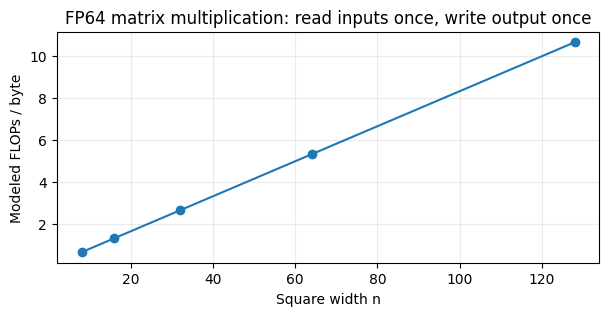

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/dongxi_llms').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from dongxi_llms.systems_performance_lab import MatmulLedger, attention_ledger, roofline, benchmark_matmul, checkpoint_audit, decoder_phase_ledger
from dongxi_llms.decoder_lab import DecoderConfig
ledger=MatmulLedger(2,3,4,8).report()
print(ledger)
sizes=np.array([8,16,32,64,128])
intensities=[MatmulLedger(int(x),int(x),int(x),8).report()['arithmetic_intensity'] for x in sizes]
fig,ax=plt.subplots(figsize=(7,3));ax.plot(sizes,intensities,'o-');ax.set(xlabel='Square width n',ylabel='Modeled FLOPs / byte',title='FP64 matrix multiplication: read inputs once, write output once');ax.grid(alpha=.25);plt.show()

### Reference explanation

There are8 output entries, each with3 multiply-adds:48 FLOPs. The6+12+8 FP64 values occupy208 modeled bytes, so intensity is48/208≈0.231 FLOPs/byte. For square width n, this model gives2n³/(24n²)=n/12. The line describes a reuse assumption, not measured cache traffic. A tiny matrix can be dominated by dispatch overhead even when the algebraic count is correct. Doubling only rows changes the balance between one reused B and the other arrays; recompute the denominator.

## 2. Attention trades materialization for rereads

### Prediction

If query tiles shrink, which term grows: score storage or repeated K/V reads? Predict a case where the blockwise traffic model is worse than the dense model.

### Checkpoint

Compare query tiles8 and32. Keep batch, heads, head width and element size fixed. Identify the read policy behind each curve.

### Reference solution

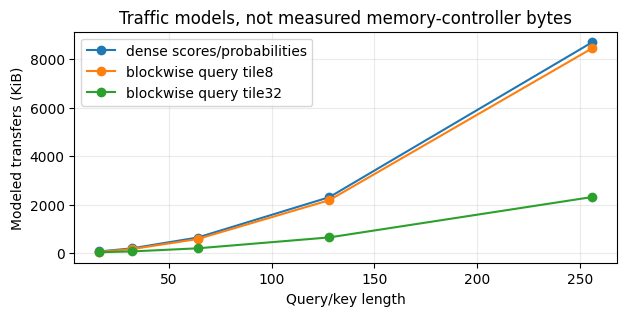

{'dense_score_value_matmul_flops': 4194304, 'dense_score_probability_payload_bytes': 1048576, 'modeled_dense_io_bytes': 2359296, 'modeled_blockwise_io_bytes': 659456, 'assumptions': ['Dense: write/read scores and write/read probabilities once.', 'Blockwise: each query block reads all K/V once; row logsumexp written once.', 'Inputs/output included; mask, softmax arithmetic and actual cache behavior excluded.', 'These are modeled transfers, not measured DRAM/HBM traffic.']}


In [2]:
lengths=[16,32,64,128,256]
dense=[];tile8=[];tile32=[]
for length in lengths:
    a=attention_ledger(1,4,length,length,16,query_tile=8,element_bytes=8)
    b=attention_ledger(1,4,length,length,16,query_tile=32,element_bytes=8)
    dense.append(a['modeled_dense_io_bytes']);tile8.append(a['modeled_blockwise_io_bytes']);tile32.append(b['modeled_blockwise_io_bytes'])
fig,ax=plt.subplots(figsize=(7,3));
for y,label in [(dense,'dense scores/probabilities'),(tile8,'blockwise query tile8'),(tile32,'blockwise query tile32')]:ax.plot(lengths,np.array(y)/1024,'o-',label=label)
ax.set(xlabel='Query/key length',ylabel='Modeled transfers (KiB)',title='Traffic models, not measured memory-controller bytes');ax.legend();ax.grid(alpha=.25);plt.show()
print(attention_ledger(1,4,128,128,16,query_tile=32,element_bytes=8))

### Reference explanation

Dense scores and probabilities each incur one modeled write and read. A query block holds its row statistics but rereads all K/V; more query blocks therefore raise that term. Eliminating the quadratic score array does not guarantee fewer transferred bytes for every tile policy. Actual cache reuse, tiling, masks and kernel scheduling can change these models. The online reference in the next notebook proves numerical equivalence, separately from this IO estimate.

## 3. A roofline is a bound under declared inputs

### Prediction

For a hypothetical FP64 instrument with compute100 GFLOP/s and bandwidth20 GB/s, where is the ridge? Can an actual CPU timing be called utilization without a compatible measured or documented peak?

### Checkpoint

Read the hypothetical bound and separate CPU timing panel. Change bandwidth alone; then compare the synchronized helper with the intentionally incomplete queue timer.

### Reference solution

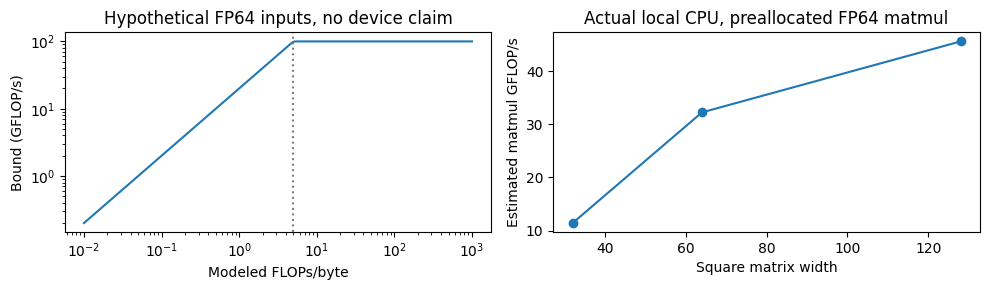

At submission timer stop: completed= []
After completion boundary: completed= ['result']
Raw repeated CPU seconds: [[6.336020305752754e-06, 6.00004568696022e-06, 5.856039933860302e-06, 5.743931978940964e-06, 5.728099495172501e-06, 5.712034180760384e-06, 5.712034180760384e-06], [1.627206802368164e-05, 1.625495497137308e-05, 1.6256002709269524e-05, 1.6239937394857407e-05, 1.6207923181355e-05, 1.628801692277193e-05, 1.6223988495767117e-05], [9.236799087375402e-05, 9.172700811177492e-05, 9.247998241335154e-05, 9.209499694406986e-05, 9.185599628835917e-05, 9.193492587655783e-05, 9.118393063545227e-05]]


In [3]:
intensity=np.logspace(-2,3,150)
bound=[roofline(float(x),100e9,20e9)/1e9 for x in intensity]
measured=[benchmark_matmul(int(x),int(x),int(x),dtype=__import__('torch').float64) for x in [32,64,128]]
fig,axes=plt.subplots(1,2,figsize=(10,3));axes[0].loglog(intensity,bound);axes[0].axvline(5,color='gray',linestyle=':');axes[0].set(xlabel='Modeled FLOPs/byte',ylabel='Bound (GFLOP/s)',title='Hypothetical FP64 inputs, no device claim')
axes[1].plot([r['ledger']['rows'] for r in measured],[r['estimated_matmul_flops_per_second']/1e9 for r in measured],'o-');axes[1].set(xlabel='Square matrix width',ylabel='Estimated matmul GFLOP/s',title='Actual local CPU, preallocated FP64 matmul');plt.tight_layout();plt.show()
# An authored queue illustrates asynchronous submission; it is not a CUDA benchmark.
queue=[];completed=[]
queue.append(lambda:completed.append('result'))
print('At submission timer stop: completed=',completed)
for work in queue:work()
print('After completion boundary: completed=',completed)
print('Raw repeated CPU seconds:',[r['timing']['seconds'] for r in measured])

### Reference explanation

The ridge is100/20=5 FLOPs/byte. The left panel uses hypothetical inputs and cannot calibrate the measured CPU in the right panel. The CPU values divide the counted2mkn work by a measured matmul interval; they are estimated matmul throughput, with raw repetitions retained. They do not measure all executed instructions. The queue control stops before work completes: the measured submission interval answers another question. CUDA timing requires synchronization before starting and after completing the selected work. The runner prepares that separate device profile; no GPU was launched by this cell.

## 4. Checkpointing changes when activations are obtained

### Prediction

Can the same loss and gradient result from retaining fewer forward tensors? Predict the number of repeated block entries for two blocks, then explain why recomputation can cost time.

### Checkpoint

Compare the existing StoriesDecoder checkpoint switch using identical weights, tokens and FP64. Distinguish logical saved-tensor bytes from deduplicated backing storage and from peak memory.

### Reference solution

Loss difference: 0.0 gradient max absolute difference: 0.0


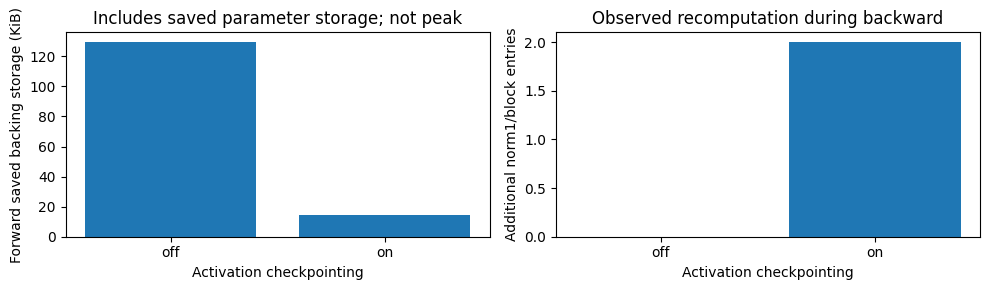

[(False, 2, 2, 158856), (True, 2, 4, 19080)]


In [4]:
audit=checkpoint_audit()
print('Loss difference:',audit['loss_abs_difference'],'gradient max absolute difference:',audit['gradient_max_abs_difference'])
labels=['off','on'];arms=audit['arms']
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].bar(labels,[r['unique_backing_storage_bytes']/1024 for r in arms]);axes[0].set(xlabel='Activation checkpointing',ylabel='Forward saved backing storage (KiB)',title='Includes saved parameter storage; not peak')
axes[1].bar(labels,[r['recomputed_block_entries'] for r in arms]);axes[1].set(xlabel='Activation checkpointing',ylabel='Additional norm1/block entries',title='Observed recomputation during backward');plt.tight_layout();plt.show()
print([(r['checkpointing'],r['forward_block_entries'],r['total_block_entries'],r['logical_saved_tensor_bytes']) for r in arms])

### Reference explanation

Checkpointing invokes the same existing non-reentrant implementation, rather than a new approximation. Forward begins two blocks in both arms; backward re-enters both blocks only in the checkpointed arm. The reference declares loss/gradient absolute tolerance1e-12 before any profile. Saved-tensor hooks count what autograd requests during forward; shared backing storage is deduplicated, while parameter storage is still included. A process or CUDA allocator peak needs a separate instrument. Fewer saved bytes plus more work does not establish a speedup, and the bar is specific to this fixture.

## 5. Prefill and one new token answer different cost questions

### Prediction

With a fixed prefix, should a cached new token recompute all old-token projections? Which quantities still grow with prefix length?

### Checkpoint

Reuse the existing dense parameter/KV/FLOP estimator. Compare full prefill with one appended token, including reads of the existing cache. Keep model dimensions fixed.

### Reference solution

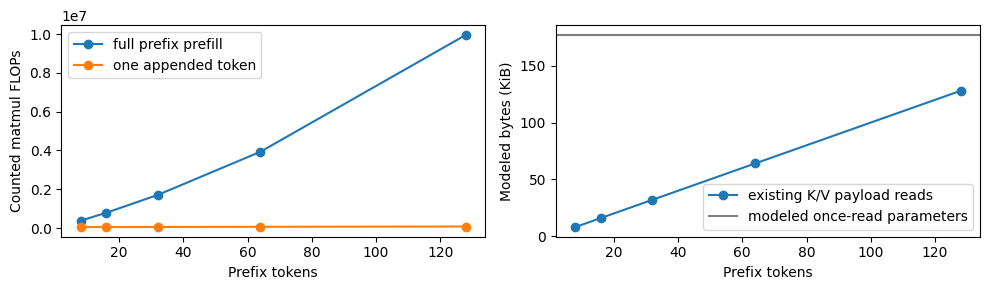

{'prefill': {'parameters': 22688, 'dense_forward_matmul_flops': 9961472, 'logical_kv_bytes': 131072}, 'cached_new_token_matmul_flops': 78080, 'decode_cache_read_bytes': 131072, 'decode_cache_append_bytes': 1024, 'modeled_parameter_read_bytes': 181504, 'modeled_decode_intensity': 0.24897959183673468, 'assumption': 'New token attends prefix plus itself; projections/MLP/head once; parameter payload read once; excludes softmax, elementwise ops, cache effects, non-KV activations and allocation'}


In [5]:
c=DecoderConfig(vocab=64,width=32,heads=4,kv_heads=4,head_dim=8,layers=2,hidden=64,max_length=129,modern=True,qk_norm=False)
lengths=[8,16,32,64,128];rows=[decoder_phase_ledger(c,1,x,element_bytes=8) for x in lengths]
fig,axes=plt.subplots(1,2,figsize=(10,3));axes[0].plot(lengths,[r['prefill']['dense_forward_matmul_flops'] for r in rows],'o-',label='full prefix prefill');axes[0].plot(lengths,[r['cached_new_token_matmul_flops'] for r in rows],'o-',label='one appended token');axes[0].set(xlabel='Prefix tokens',ylabel='Counted matmul FLOPs');axes[0].legend()
axes[1].plot(lengths,[r['decode_cache_read_bytes']/1024 for r in rows],'o-',label='existing K/V payload reads');axes[1].axhline(rows[0]['modeled_parameter_read_bytes']/1024,label='modeled once-read parameters',color='gray');axes[1].set(xlabel='Prefix tokens',ylabel='Modeled bytes (KiB)');axes[1].legend();plt.tight_layout();plt.show()
print(rows[-1])

### Reference explanation

One cached query attends prefix+itself while its projections, MLP and vocabulary head run once. Its attention arithmetic and K/V read payload grow with prefix length; parameter payload remains fixed under the explicitly modeled once-read policy. Prefill operates on every prefix token. These curves reuse the course cost formulas and exclude norms, softmax, allocator overhead and backward. Exact cached/full logits are already independently tested by the cache labs. This ledger explains the work difference; it does not prove a throughput ratio.

## Evidence and next step

Submit a ledger with units, one prediction and one controlled change. Link the actual timing or saved-storage receipt and state the inference it does not support. The [focused solutions](SYSTEMS_SOLUTIONS.md) connect these questions to AssignmentC. Run machine-specific profiles through the prepared runner and retain device, precision, repetitions and memory semantics; changing the backend label alone is not evidence that a fused kernel ran.